# Анализ данных вина с использованием KNN и других классификаторов

## Обзор проекта

Этот проект демонстрирует полный процесс анализа данных и построения моделей машинного обучения на наборе данных о вине. Мы используем различные алгоритмы классификации и сравниваем их производительность.

## Импорт библиотек

Основные библиотеки для анализа данных и визуализации:

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

## Импорт библиотек машинного обучения

Библиотеки scikit-learn для построения моделей:

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize

## Загрузка и предварительный анализ данных

Загружаем набор данных о вине и создаем DataFrame:

In [ ]:
from sklearn.datasets import load_wine
wine = load_wine()

# Создание DataFrame
wine_df = pd.DataFrame(wine.data, columns=wine.feature_names)
wine_df['target'] = wine.target
wine_df['name'] = wine_df['target'].apply(lambda x: wine.target_names[x])
wine_df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


## Количество образцов в кажом классе

In [ ]:
print(wine_df['name'].value_counts())

name
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


## Визуализация данных

Исследуем данные с помощью различных графиков:

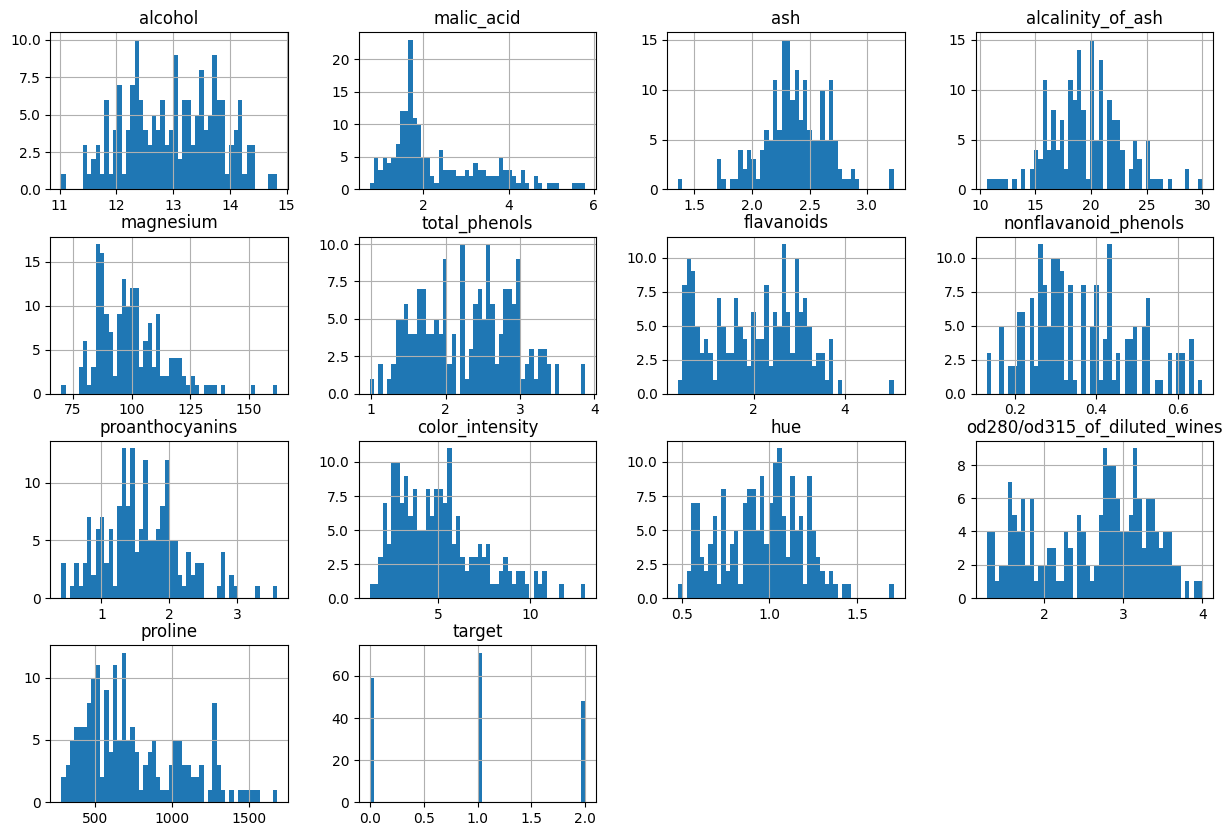

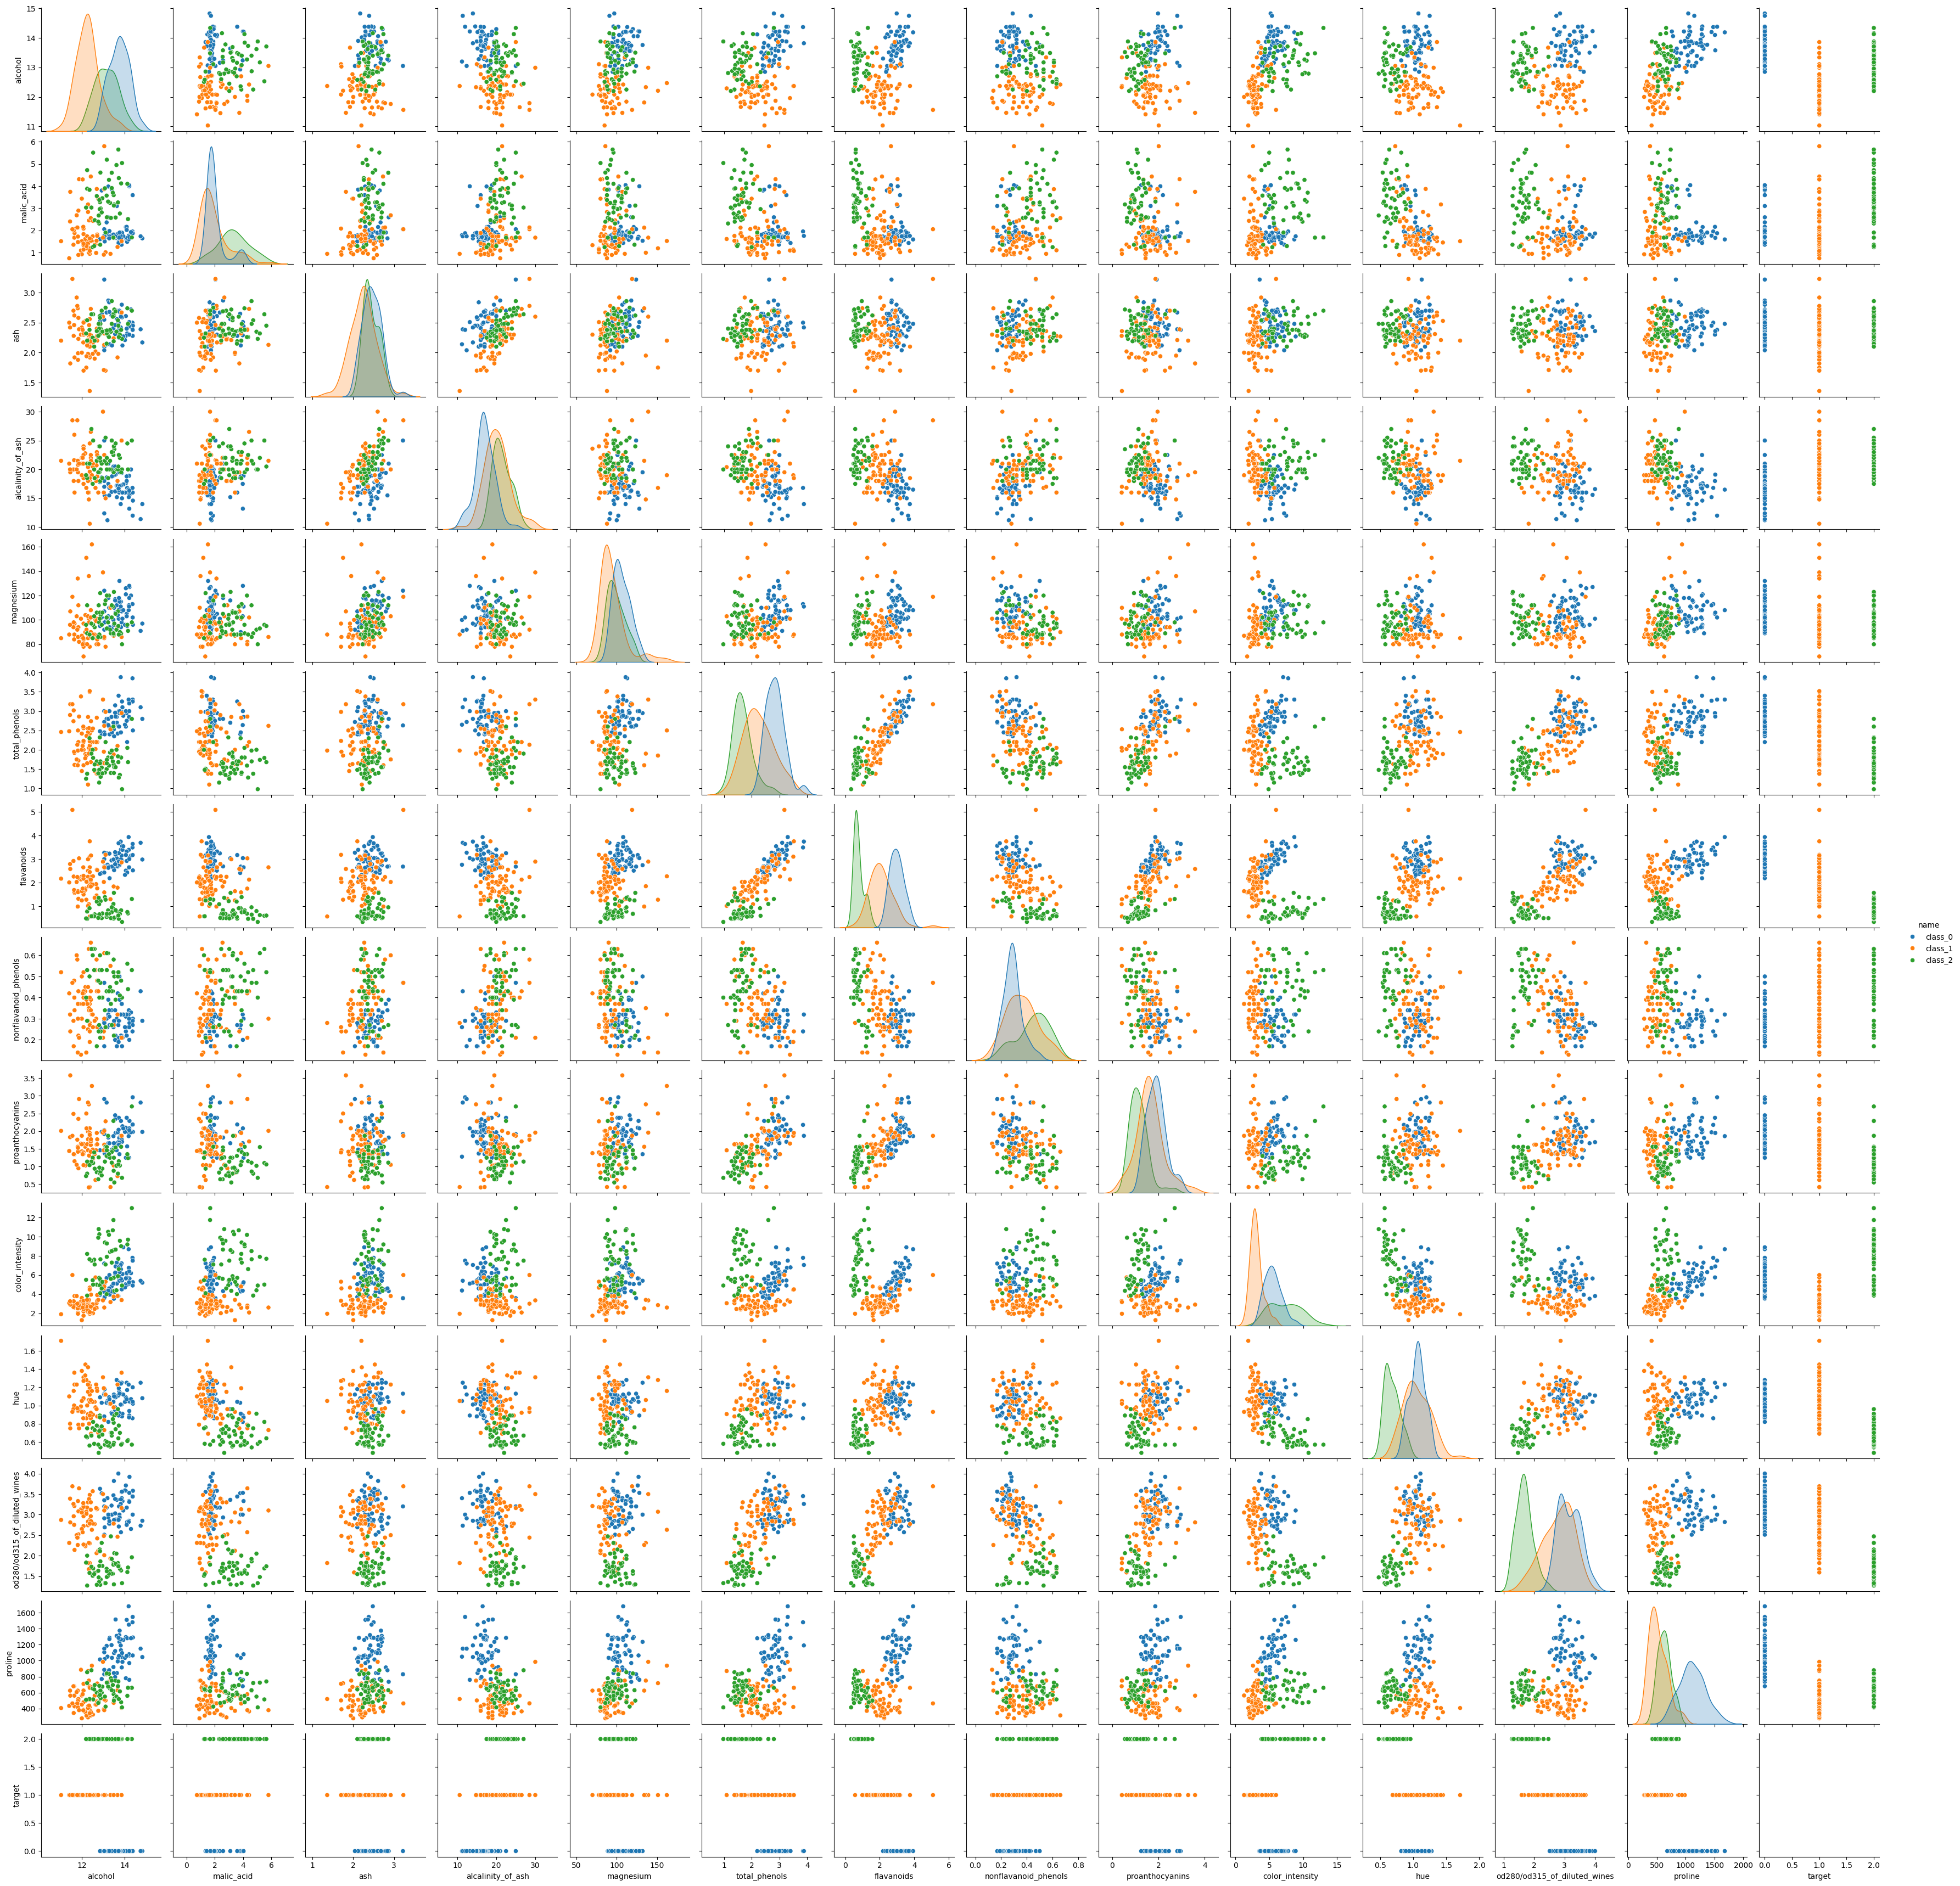

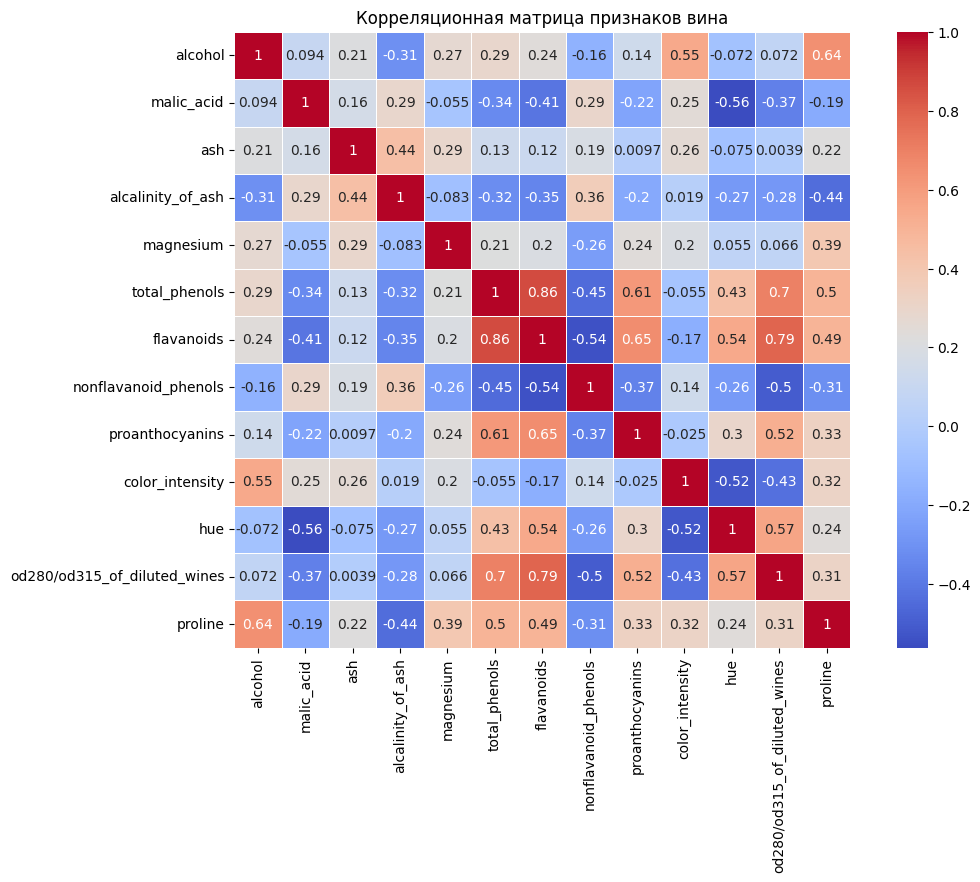

In [ ]:
# Гистограммы распределения признаков
wine_df.hist(figsize=(15, 10), bins=50)
plt.show()

# Парные графики для анализа взаимосвязей
sns.pairplot(wine_df, hue='name')
plt.show()

# Корреляционная матрица
corr = wine_df[wine.feature_names].corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, square=True, annot=True, linewidths=.5, cmap='coolwarm')
plt.title('Корреляционная матрица признаков вина')
plt.show()

## Подготовка данных для моделирования

Разделяем данные на обучающую и тестовую выборки, масштабируем признаки:

In [ ]:
X = wine_df[wine.feature_names]
y = wine_df['target']

from sklearn.preprocessing import StandardScaler

# Масштабирование признаков для улучшения производительности KNN
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Разделение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=19)

## Построение модели KNN с подбором гиперпараметров

Используем GridSearchCV для поиска оптимальных параметров KNN:

In [ ]:
param_grid = {
    'n_neighbors': list(range(1, 31)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)
print("Лучшие параметры:", grid_search.best_params_)

best_knn = grid_search.best_estimator_

Fitting 5 folds for each of 180 candidates, totalling 900 fits
Лучшие параметры: {'metric': 'manhattan', 'n_neighbors': 7, 'weights': 'uniform'}


## Оценка производительности KNN модели

Обучаем модель с лучшими параметрами и оцениваем ее производительность:

In [ ]:
# Используем найденные лучшие параметры
best_knn = grid_search.best_estimator_

# Обучение модели с лучшими параметрами
best_knn.fit(X_train, y_train)

# Предсказание на тестовой выборке
y_pred = best_knn.predict(X_test)

# Оценка модели
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        17
           1       1.00      0.88      0.93        24
           2       0.81      1.00      0.90        13

    accuracy                           0.94        54
   macro avg       0.94      0.96      0.94        54
weighted avg       0.95      0.94      0.95        54


Accuracy Score: 0.9444444444444444


## Кросс-валидация

Проверяем устойчивость модели с помощью кросс-валидации:

In [ ]:
cv_scores = cross_val_score(best_knn, X_scaled, y, cv=5)
print('Cross-validation scores:', cv_scores)
print('Mean cross-validation score:', np.mean(cv_scores))
print('Standard deviation:', np.std(cv_scores))

Cross-validation scores: [0.91666667 0.94444444 1.         1.         0.94285714]
Mean cross-validation score: 0.9607936507936508
Standard deviation: 0.03349770508416615


## Сравнение с другими алгоритмами

Сравниваем KNN с другими популярными алгоритмами классификации:

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

# Random Forest
rf = RandomForestClassifier(random_state=19)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

# Support Vector Classifier
svc = SVC(probability=True, random_state=19)
svc.fit(X_train, y_train)
svc_pred = svc.predict(X_test)
print("SVC Accuracy:", accuracy_score(y_test, svc_pred))

# Logistic Regression
log_reg = LogisticRegression(random_state=19, max_iter=1000)
log_reg.fit(X_train, y_train)
log_reg_pred = log_reg.predict(X_test)
print("Logistic Regression Accuracy:", accuracy_score(y_test, log_reg_pred))

# Gradient Boosting Classifier
gbc = GradientBoostingClassifier(random_state=19)
gbc.fit(X_train, y_train)
gbc_pred = gbc.predict(X_test)
print("Gradient Boosting Classifier Accuracy:", accuracy_score(y_test, gbc_pred))

Random Forest Accuracy: 0.9629629629629629
SVC Accuracy: 0.9629629629629629
Logistic Regression Accuracy: 0.9444444444444444
Gradient Boosting Classifier Accuracy: 0.8703703703703703


## Ансамблевая модель (Voting Classifier)

Объединяем несколько моделей в ансамбль для улучшения производительности:

In [ ]:
from sklearn.ensemble import VotingClassifier

voting_clf = VotingClassifier(
    estimators=[
        ('knn', best_knn),
        ('rf', rf),
        ('svc', svc),
        ('log_reg', log_reg),
        ('gbc', gbc),
    ],
    voting='soft'
)

voting_clf.fit(X_train, y_train)
voting_pred = voting_clf.predict(X_test)
print("Voting Classifier Accuracy:", accuracy_score(y_test, voting_pred))

Voting Classifier Accuracy: 0.9629629629629629


## Анализ важности признаков

Определяем наиболее значимые признаки с помощью Random Forest:

Важность признаков (по убыванию):
1. flavanoids: 0.1994
2. proline: 0.1739
3. color_intensity: 0.1257
4. od280/od315_of_diluted_wines: 0.1240
5. alcohol: 0.1149
6. hue: 0.0731
7. magnesium: 0.0428
8. malic_acid: 0.0363
9. total_phenols: 0.0346
10. alcalinity_of_ash: 0.0300
11. ash: 0.0209
12. proanthocyanins: 0.0157
13. nonflavanoid_phenols: 0.0086


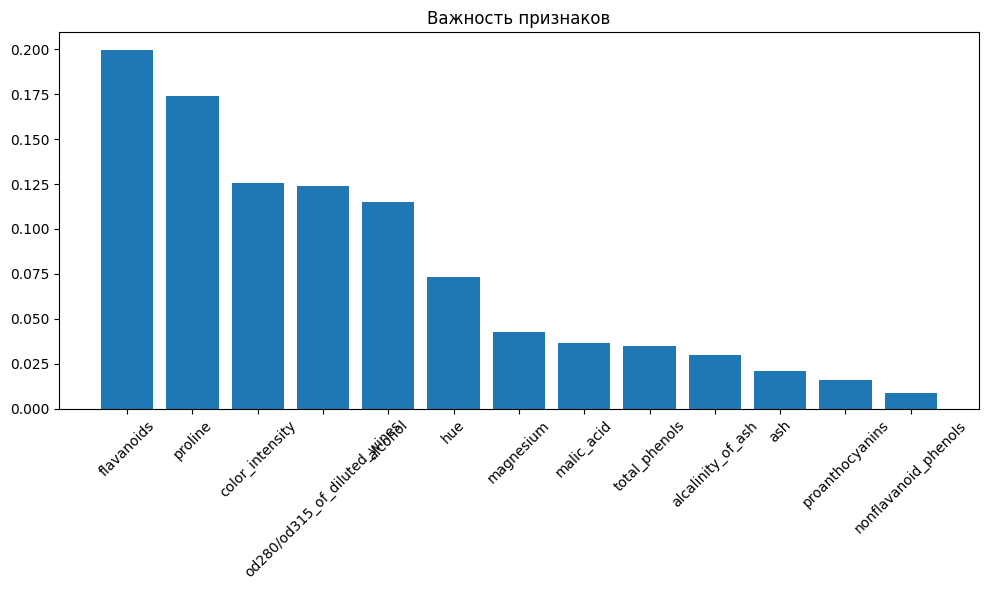

In [ ]:
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

print("Важность признаков (по убыванию):")
for i in range(X.shape[1]):
    print(f"{i+1}. {wine.feature_names[indices[i]]}: {importances[indices[i]]:.4f}")

# Визуализация важности признаков
plt.figure(figsize=(10, 6))
plt.title('Важность признаков')
plt.bar(range(X.shape[1]), importances[indices], align='center')
plt.xticks(range(X.shape[1]), [wine.feature_names[i] for i in indices], rotation=45)
plt.tight_layout()
plt.show()

## Матрица ошибок

Визуализируем производительность модели с помощью матрицы ошибок:

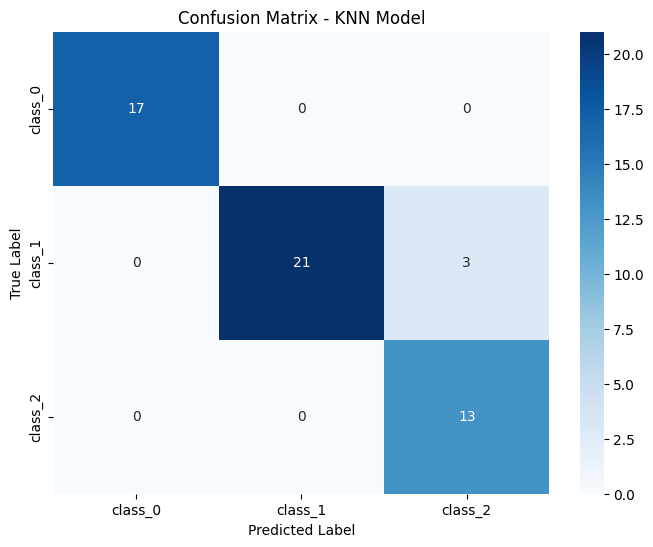

In [ ]:
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=wine.target_names, 
            yticklabels=wine.target_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - KNN Model')
plt.show()

## Детальные метрики оценки

Анализируем различные метрики качества модели:

In [ ]:
print("Micro Average (глобальный подсчет)")
print("Precision:", precision_score(y_test, y_pred, average='micro'))
print("Recall:", recall_score(y_test, y_pred, average='micro'))
print("F1-Score:", f1_score(y_test, y_pred, average='micro'))

print("\n=== Macro Average (среднее по классам) ===")
print("Precision:", precision_score(y_test, y_pred, average='macro'))
print("Recall:", recall_score(y_test, y_pred, average='macro'))
print("F1-Score:", f1_score(y_test, y_pred, average='macro'))

print("\n=== Weighted Average (взвешенное по поддержке) ===")
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1-Score:", f1_score(y_test, y_pred, average='weighted'))

Micro Average (глобальный подсчет)
Precision: 0.9444444444444444
Recall: 0.9444444444444444
F1-Score: 0.9444444444444444

=== Macro Average (среднее по классам) ===
Precision: 0.9375
Recall: 0.9583333333333334
F1-Score: 0.943295019157088

=== Weighted Average (взвешенное по поддержке) ===
Precision: 0.9548611111111112
Recall: 0.9444444444444444
F1-Score: 0.9454661558109834


## ROC-кривые для всех моделей

Сравниваем производительность всех моделей с помощью ROC-кривых:

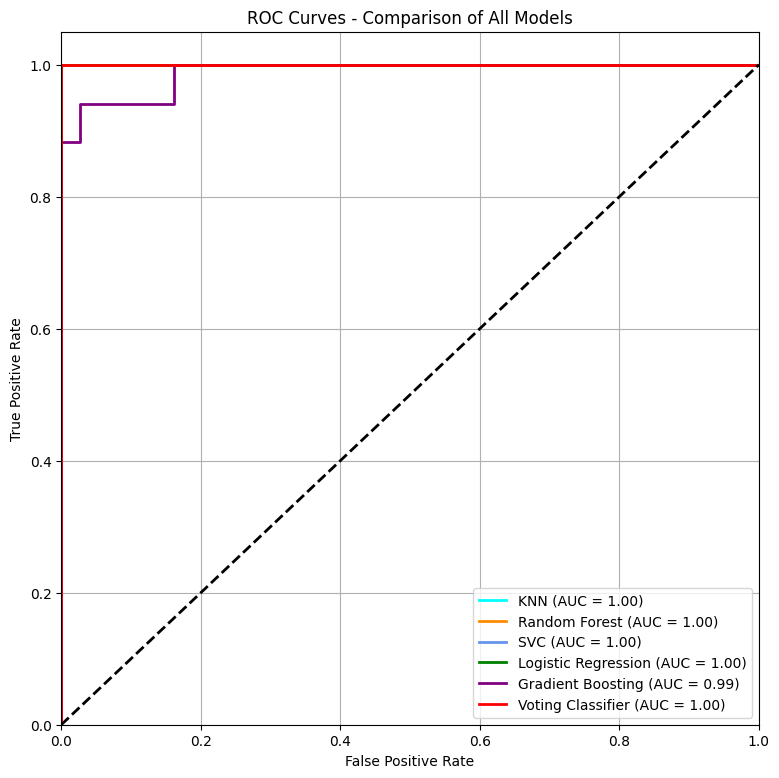

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Бинаризация целевой переменной для многоклассовой ROC
y_test_bin = label_binarize(y_test, classes=np.unique(y))

# Список моделей для сравнения
models = {
    'KNN': best_knn,
    'Random Forest': rf,
    'SVC': svc,
    'Logistic Regression': log_reg,
    'Gradient Boosting': gbc,
    'Voting Classifier': voting_clf
}

# Построение ROC-кривых
plt.figure(figsize=(9, 9))
colors = ['aqua', 'darkorange', 'cornflowerblue', 'green', 'purple', 'red']

for (name, model), color in zip(models.items(), colors):
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test)
    else:
        continue
    
    # Вычисление ROC-кривой и AUC для каждого класса
    fpr = {}
    tpr = {}
    roc_auc = {}
    
    for i in range(len(wine.target_names)):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    
    # Построение ROC-кривой для первого класса (в качестве примера)
    plt.plot(fpr[0], tpr[0], color=color, lw=2,
             label=f'{name} (AUC = {roc_auc[0]:.2f})')

# Настройки графика
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Comparison of All Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## Выводы

### Основные результаты:

1. **Качество моделей**: Все модели показали высокую точность классификации
2. **KNN производительность**: Модель KNN демонстрирует конкурентные результаты после тщательного подбора гиперпараметров
3. **Ансамбли**: Voting Classifier часто показывает лучшие результаты за счет комбинации сильных сторон отдельных моделей
4. **Важные признаки**: Анализ важности признаков помогает понять, какие характеристики вина наиболее значимы для классификации

### Рекомендации:
- Для данного набора данных KNN является хорошим выбором благодаря своей простоте и интерпретируемости
- Масштабирование признаков критически важно для KNN
- Ансамблевые методы могут обеспечить дополнительное улучшение производительности